# Run at the Start

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
# loading dataset, display 10 samples of it
df = pd.read_csv('../Data/WA_Fn-UseC_-Telco-Customer-Churn.csv').drop(columns=['customerID'])
df.sample(10, random_state=42)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No
1263,Female,1,Yes,No,68,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.60,6127.6,Yes
3732,Female,0,Yes,Yes,23,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),77.15,1759.4,No
1672,Male,0,Yes,Yes,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),72.10,5016.65,No
811,Male,0,No,No,70,Yes,Yes,Fiber optic,Yes,No,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),104.00,7250.15,Yes
2526,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.40,19.4,Yes


In [3]:
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Dataset structure

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="str").columns

In [5]:
print(f'Dataset Shape -> Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print('Dataset Dims: ', df.ndim)

print("\nNumerical columns:")
print(numeric_cols.tolist())

print("\nCategorical columns:")
print(categorical_cols.tolist())

Dataset Shape -> Rows: 7043, Columns: 20
Dataset Dims:  2

Numerical columns:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [7]:
print('Unique Values for each Feature:')
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].nunique(), "unique values")
    print(df[col].value_counts(dropna=False).head(20))

Unique Values for each Feature:

--- gender ---
2 unique values
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
2 unique values
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
2 unique values
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
2 unique values
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
2 unique values
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
3 unique values
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
3 unique values
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
3 unique values
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
3

# Dataset Stats

In [8]:
df.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


# Dataset Quality

*Missing Values*

In [9]:
missing_percent = df.isnull().mean() * 100
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent
})

print(missing_table.sort_values("Missing %", ascending=False))

                  Missing Count  Missing %
TotalCharges                 11   0.156183
gender                        0   0.000000
Partner                       0   0.000000
SeniorCitizen                 0   0.000000
Dependents                    0   0.000000
tenure                        0   0.000000
MultipleLines                 0   0.000000
PhoneService                  0   0.000000
OnlineSecurity                0   0.000000
OnlineBackup                  0   0.000000
DeviceProtection              0   0.000000
InternetService               0   0.000000
TechSupport                   0   0.000000
StreamingTV                   0   0.000000
Contract                      0   0.000000
StreamingMovies               0   0.000000
PaperlessBilling              0   0.000000
PaymentMethod                 0   0.000000
MonthlyCharges                0   0.000000
Churn                         0   0.000000


In [10]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 22


# Univariate analysis

*Using Histogram*


 ---------------------------------- tenure ----------------------------------


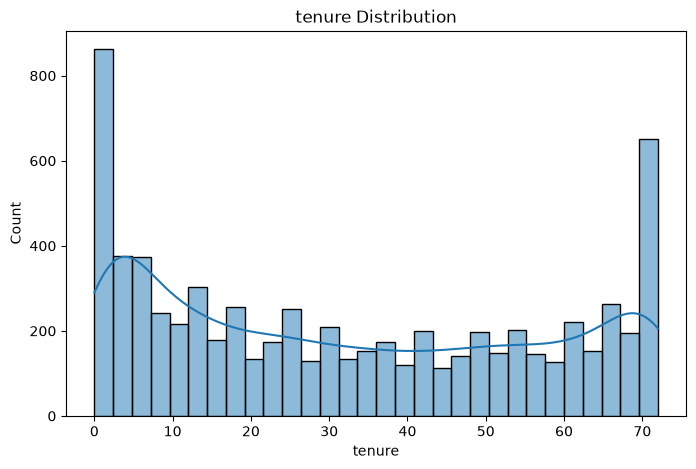


 ---------------------------------- MonthlyCharges ----------------------------------


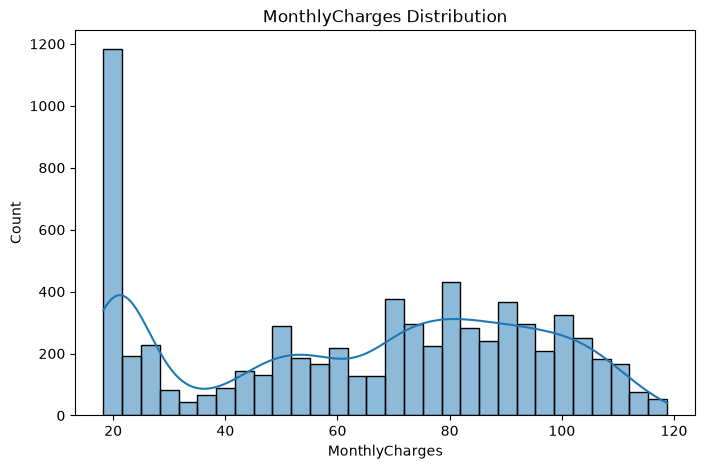


 ---------------------------------- TotalCharges ----------------------------------


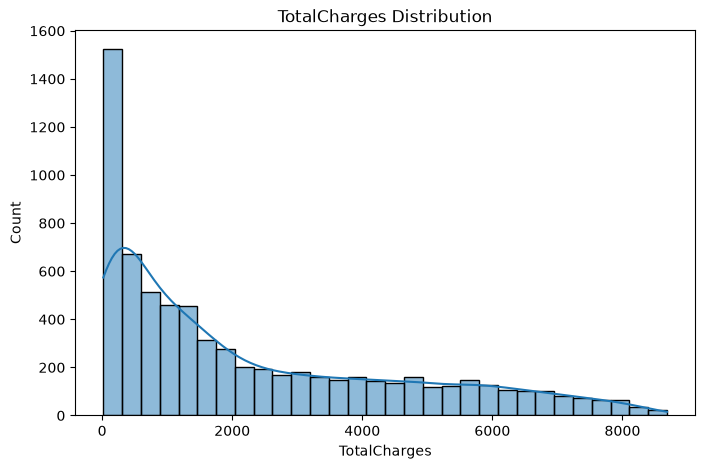

In [11]:
for i in numeric_cols:
    print("\n",'-'*34,i,'-'*34)
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=i, bins=30, kde=True)
    plt.title(f"{i} Distribution")
    plt.show()

*Using Boxplots*


 ---------------------------------- tenure ----------------------------------


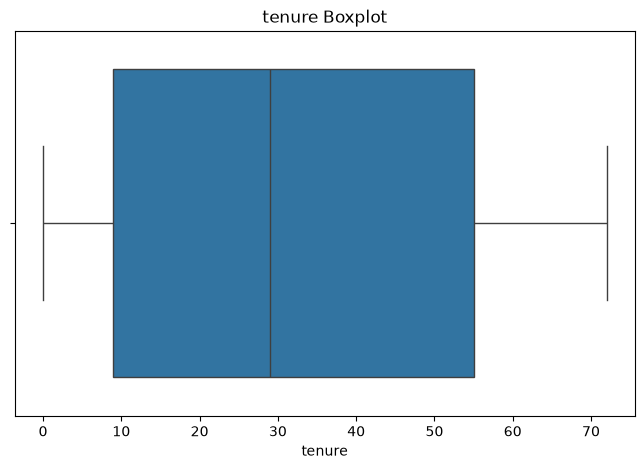


 ---------------------------------- MonthlyCharges ----------------------------------


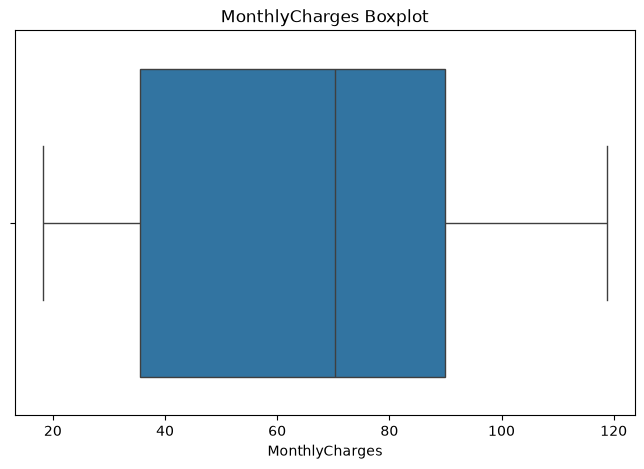


 ---------------------------------- TotalCharges ----------------------------------


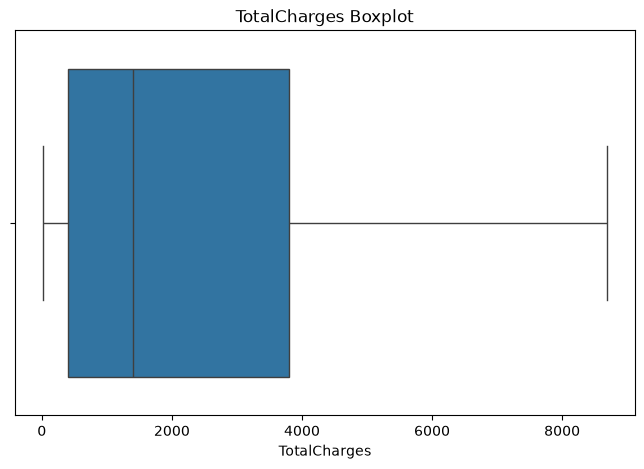

In [12]:
for i in numeric_cols:
    print("\n",'-'*34,i,'-'*34)
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=i)
    plt.title(f"{i} Boxplot")
    plt.show()

*Measure skewness*

In [19]:
skewness = df[numeric_cols].skew().sort_values()
print(skewness)

MonthlyCharges   -0.220524
tenure            0.239540
TotalCharges      0.961642
dtype: float64


*Outliers*

In [13]:
for i in numeric_cols:
    print("\n",'-'*34,i,'-'*34)
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("Lower:", lower_bound)
    print("Upper:", upper_bound)

    outliers = df[(df[i] < lower_bound) |(df[i] > upper_bound)]

    print(outliers)
    print("Number of outliers:", len(outliers))


 ---------------------------------- tenure ----------------------------------
Lower: -60.0
Upper: 124.0
Empty DataFrame
Columns: [gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []
Number of outliers: 0

 ---------------------------------- MonthlyCharges ----------------------------------
Lower: -46.02499999999999
Upper: 171.375
Empty DataFrame
Columns: [gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []
Number of outliers: 0

 ---------------------------------- TotalCharges ----------------------------------
Lower: -4688.481250000001
Up

*Suspicious Values*

For Negative Numarical Values

In [14]:
for i in numeric_cols:
    print("\n",'-'*20,i,'-'*20)
    print(df[df[i] < 0])


 -------------------- tenure --------------------
Empty DataFrame
Columns: [gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

 -------------------- MonthlyCharges --------------------
Empty DataFrame
Columns: [gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

 -------------------- TotalCharges --------------------
Empty DataFrame
Columns: [gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract

# Target Variable

In [15]:
y = 'Churn'

In [16]:
print(df[y].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


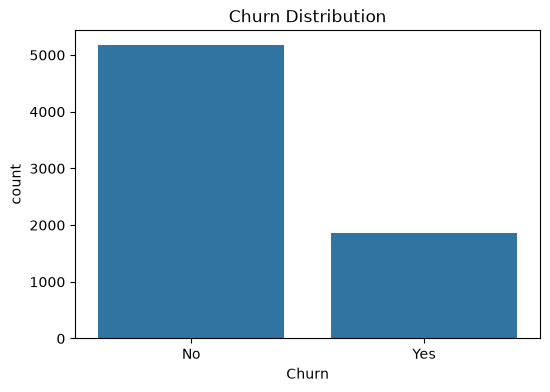

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=y)

plt.title(f"{y} Distribution")
plt.show()